# Difração de Raios X: Atividade I

Análise do padrão de DRX de um metal com estrutura cúbica.

**Etapas do roteiro cobertas neste notebook**

| Item | O que é feito | Seção |
|---|---|---|
| I | Plotar o difratograma | 3 |
| II | Normalizar as intensidades (pico mais intenso = 100%) | 4 |
| III | Determinar 2θ e intensidade relativa de cada pico | 5 |
| IV | Calcular a distância interplanar $d_{hkl}$ (Lei de Bragg) | 6 |
| V | Determinar o tipo de rede cúbica (CS, CCC ou CFC) | 7 |
| VI e VII | Indexar os picos com os índices de Miller (hkl) | 8 e 9 |
| VIII | Calcular o parâmetro de rede $a$, a média e o erro | 8 |
| IX | Identificar o metal e comparar com a literatura | 10 |
| X | Desenhar a estrutura e os planos dos dois picos mais intensos | 11 |
| d | Efeito de um elemento de liga (solução sólida) no difratograma | 12 |
| e | Informações do difratograma ligadas à fração volumétrica das fases | 13 |
| – | Resumo de todos os resultados | 14 |

---

### Fundamentos: o que é um difratograma?

Os raios X são ondas eletromagnéticas com comprimento de onda $\lambda$ da ordem de 0,1 nm, a mesma ordem de grandeza das distâncias entre os planos de átomos de um cristal. Por isso o cristal funciona como uma **rede de difração**: os raios espalhados por planos atômicos paralelos interferem entre si. A interferência é construtiva apenas em ângulos bem definidos, e é nesses ângulos que surgem os picos.

No **difratômetro** (geometria Bragg-Brentano θ–2θ), a amostra policristalina (pó) é irradiada por um feixe monocromático. A fonte e o detector se movem de modo que o ângulo de incidência θ seja sempre igual ao de reflexão. O detector registra a intensidade em função de **2θ**, que é o ângulo entre o feixe incidente e o difratado. Como a amostra tem milhares de grãos com orientações aleatórias, sempre há grãos com cada família de planos (hkl) na orientação certa para difratar.

O **difratograma** é o gráfico intensidade × 2θ. Ele contém:
- a **posição** dos picos (2θ), que depende das distâncias interplanares e portanto da geometria da célula unitária;
- a **intensidade** dos picos, que depende dos átomos presentes e de suas posições na célula (fator de estrutura), da multiplicidade dos planos, de fatores geométricos e de eventual textura;
- a **largura** dos picos, ligada ao tamanho de cristalito, às microdeformações e ao instrumento.

In [14]:
# ---------------------------------------------------------------
# Bibliotecas utilizadas
# ---------------------------------------------------------------
import pandas as pd              # leitura do CSV e montagem das tabelas (DataFrames)
import matplotlib.pyplot as plt  # geração dos gráficos
import numpy as np               # cálculos numéricos com vetores (seno, raiz, radianos...)

# Faz os gráficos aparecerem dentro do próprio notebook, logo abaixo da célula
%matplotlib inline

## 1. Leitura dos dados

O arquivo contém duas colunas: o ângulo **2θ** (em graus) e a **intensidade** medida pelo detector (em contagens). O passo de varredura é de **0,1°**, de 0,1° até 180°, o que dá 1800 pontos.

**Atenção ao formato:** o CSV usa vírgula como separador de colunas **e** vírgula como separador decimal (padrão brasileiro). Os números decimais vêm entre aspas, por exemplo `"31,3"`, e é isso que permite ao `pandas` distinguir as duas vírgulas. Ajuste `ARQUIVO` para o caminho do arquivo no seu computador.

In [15]:
# Caminho do arquivo de dados. O prefixo r"..." (raw string) faz o Python tratar
# as barras invertidas "\" do caminho do Windows como texto comum.
ARQUIVO = r"C:\Users\bruno\OneDrive\Visual Studio Code\2026.3\Dados.csv"

# Leitura do CSV:
#   sep=","      -> colunas separadas por vírgula
#   decimal=","  -> números como "31,3" são lidos como 31.3
#   encoding     -> codificação do arquivo (o cabeçalho tem caracteres especiais: "Ângulo 2Ɵ")
df = pd.read_csv(ARQUIVO, sep=",", decimal=",", encoding="utf-8")

# Renomeia as colunas com nomes curtos e sem acentos, mais fáceis de usar no código
df.columns = ["2theta", "I"]

# Garante que a intensidade seja número real (float), necessário para a normalização
df["I"] = df["I"].astype(float)

# Conferência rápida: quantidade de pontos e faixa angular medida
print(f"{len(df)} pontos, 2θ de {df['2theta'].min()}° a {df['2theta'].max()}°")
df.head()   # mostra as 5 primeiras linhas

1800 pontos, 2θ de 0.1° a 180.0°


,2theta,I
0,0.1,76.0
1,0.2,76.0
2,0.3,76.0
3,0.4,76.0
4,0.5,76.0


## 2. Detecção dos picos e função de plotagem

### Como um pico é identificado

Fora dos picos, o difratograma tem uma **linha de base** (o *background*), que aqui vale 76 contagens. Ela vem do espalhamento incoerente, da fluorescência da amostra e do ruído do detector, e **não** carrega informação cristalográfica.

Um ponto $i$ é considerado um **pico** quando cumpre três condições:
1. é um **máximo local**, ou seja, maior que o vizinho da esquerda e maior ou igual ao da direita: $I_{i-1} < I_i \geq I_{i+1}$;
2. está **acima de um limiar**, que aqui é o fundo mais 5% da altura do maior pico. Isso descarta flutuações pequenas da linha de base;
3. está **separado de outros picos** por pelo menos 10 pontos (1°). Se houver dois máximos mais próximos que isso, fica apenas o mais alto.

A posição do pico é tomada como o ângulo de **intensidade máxima**. Como o passo é de 0,1°, a incerteza na posição é de cerca de ±0,05° em 2θ.

### Função de plotagem

Para não repetir código, a função `plotar_difratograma` desenha qualquer versão do difratograma (bruta ou normalizada), marca o ângulo de cada pico e salva a figura em PNG com 300 dpi, uma resolução adequada para o relatório.

In [16]:
def find_peaks(y, height, distance=10):
    '''
    Encontra os picos de um sinal y (feito só com numpy, sem scipy).

    Parâmetros
    ----------
    y        : vetor de intensidades
    height   : intensidade mínima para um ponto ser considerado pico
    distance : separação mínima (em número de pontos) entre dois picos

    Retorna
    -------
    Vetor com os ÍNDICES dos picos, em ordem crescente de 2θ, e um dicionário
    vazio (mantido apenas para ter o mesmo formato de saída do scipy).
    '''
    # Índices internos do vetor (o primeiro e o último ponto não têm dois vizinhos)
    i = np.arange(1, len(y) - 1)

    # Candidatos: máximos locais acima do limiar.
    # y[i] > y[i-1]   -> maior que o vizinho da esquerda
    # y[i] >= y[i+1]  -> maior ou igual ao da direita (o ">=" trata picos de topo
    #                    plano, como em 134,2° e 134,3°, que têm a mesma intensidade)
    cand = i[(y[i] > y[i - 1]) & (y[i] >= y[i + 1]) & (y[i] > height)]

    # Filtro de distância: percorre os candidatos do MAIS ALTO para o MAIS BAIXO
    # e só aceita um candidato se ele estiver longe de todos os picos já aceitos.
    picos = []
    for p in cand[np.argsort(-y[cand])]:      # argsort(-y) ordena em ordem decrescente
        if all(abs(p - q) >= distance for q in picos):
            picos.append(p)

    return np.array(sorted(picos)), {}


def plotar_difratograma(x, y, ylabel, titulo, salvar=None):
    '''
    Plota o difratograma, marca o ângulo 2θ de cada pico e (opcionalmente) salva a figura.
    Retorna os índices dos picos encontrados.
    '''
    # Limiar de detecção: linha de base + 5% da altura útil do maior pico
    fundo = y.min()
    picos, _ = find_peaks(y, height=fundo + 0.05 * (y.max() - fundo), distance=10)

    # Cria a figura (largura x altura, em polegadas) e desenha a curva
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.plot(x, y, color="#1f4e79", lw=1.2)

    # Escreve o valor de 2θ acima de cada pico.
    # A altura do rótulo alterna entre 6 e 18 pontos para que picos próximos
    # (ex.: 85,5° e 88,3°) não tenham os textos sobrepostos.
    for k, p in enumerate(picos):
        dy = 6 if k % 2 == 0 else 18
        ax.annotate(f"{x[p]:.1f}°", xy=(x[p], y[p]), xytext=(0, dy),
                    textcoords="offset points", ha="center", fontsize=9)

    # Eixos, título e grade (r"$2\theta$" é escrito em notação LaTeX)
    ax.set_xlabel(r"$2\theta$ (graus)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(titulo, fontsize=13)
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(0, y.max() * 1.12)     # 12% de folga no topo para caber os rótulos
    ax.grid(alpha=0.3)
    fig.tight_layout()

    if salvar:                          # salva em PNG de alta resolução para o relatório
        fig.savefig(salvar, dpi=300)
    plt.show()
    return picos

## 3. Difratograma: intensidade bruta (Item I)

A intensidade é dada em contagens, que é o número de fótons registrados pelo detector em cada ângulo. Esse valor absoluto depende de condições experimentais (potência do tubo, tempo de contagem por passo, quantidade de amostra), por isso é expresso em **unidades arbitrárias (u.a.)**.

Cada pico corresponde a uma **família de planos cristalinos (hkl)** que satisfaz a condição de Bragg. Picos em ângulos menores correspondem a planos mais espaçados (d maior).

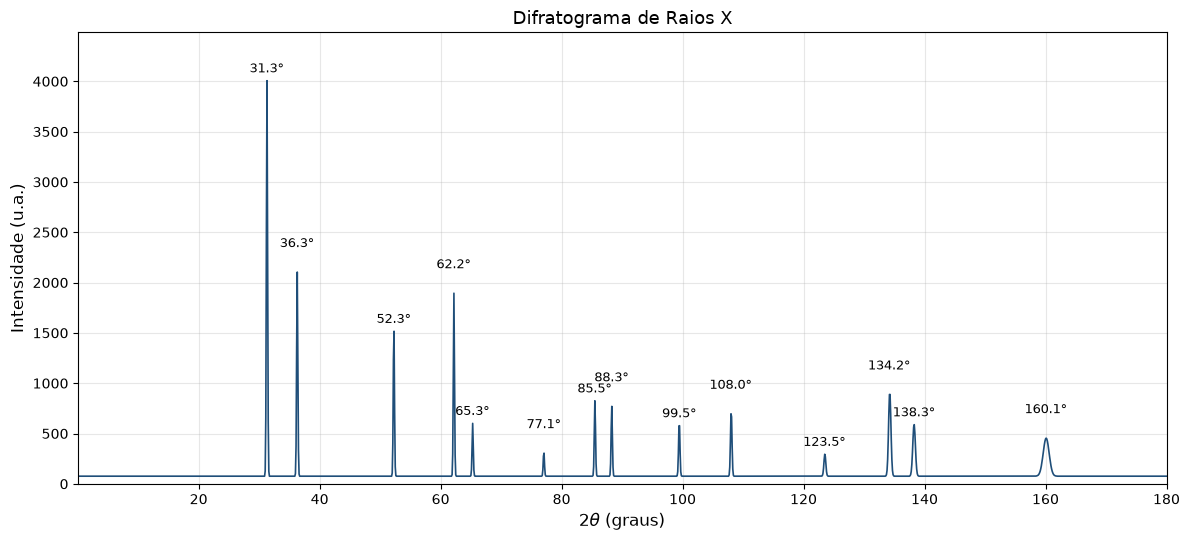

In [17]:
# Converte as colunas do DataFrame em vetores numpy (mais práticos para os cálculos)
x = df["2theta"].to_numpy()   # ângulos 2θ (graus)
y = df["I"].to_numpy()        # intensidades (contagens)

# Plota, detecta os picos e guarda os índices deles na variável "picos"
picos = plotar_difratograma(x, y, "Intensidade (u.a.)", "Difratograma de Raios X",
                            salvar="difratograma.png")

## 4. Difratograma normalizado (Item II)

Como a intensidade absoluta depende das condições de medida, o que se compara com bancos de dados (fichas ICDD/PDF) e com a literatura é a **intensidade relativa**. O pico mais intenso recebe 100% e os demais são expressos como porcentagem dele:

$$I_{rel} = 100 \cdot \frac{I}{I_{max}}$$

A normalização **não altera** a posição nem a forma dos picos, só a escala do eixo vertical.

> *Observação:* aqui a linha de base (76 contagens) não foi subtraída. Se ela for subtraída antes, $I_{rel} = 100\,(I - I_{fundo})/(I_{max} - I_{fundo})$, as intensidades relativas dos picos fracos diminuem um pouco. Vale escolher uma das convenções e indicá-la no relatório.

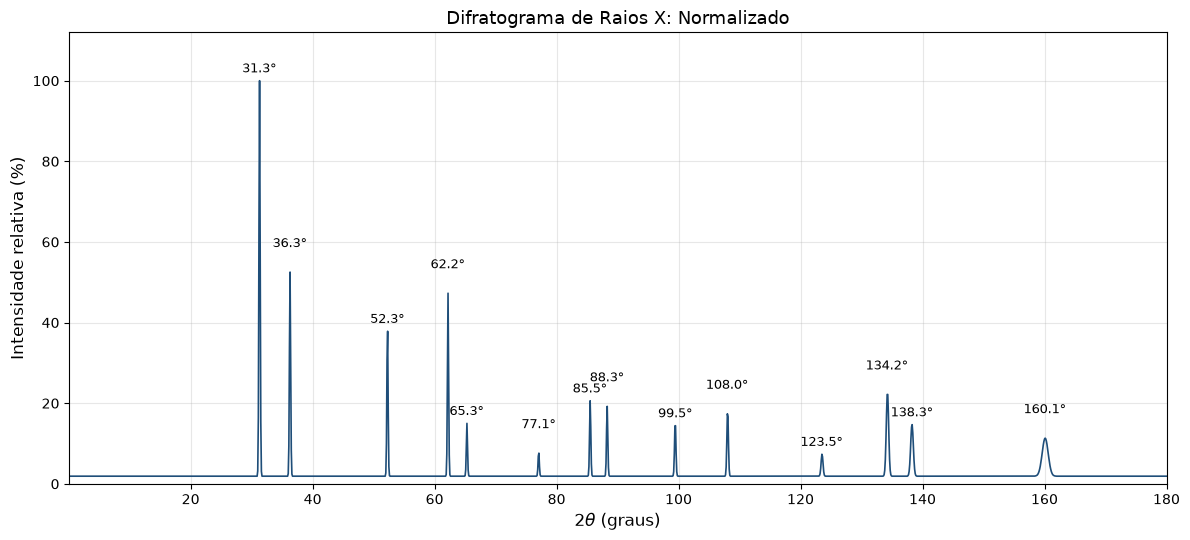

In [18]:
# Normalização: divide todas as intensidades pela máxima e multiplica por 100
y_norm = 100 * y / y.max()

# Plota a versão normalizada. O retorno é descartado com "_" porque os picos
# são os mesmos já encontrados na seção 3.
_ = plotar_difratograma(x, y_norm, "Intensidade relativa (%)",
                        "Difratograma de Raios X: Normalizado",
                        salvar="difratograma_normalizado.png")

## 5. Tabela de picos (Item III)

Para cada pico detectado são registrados a posição 2θ, a intensidade absoluta e a intensidade relativa.

As intensidades relativas **não são todas iguais** porque cada família de planos (hkl) tem:
- um **fator de estrutura** $F_{hkl}$, que soma as ondas espalhadas por todos os átomos da célula;
- uma **multiplicidade** $p$, que é o número de planos equivalentes por simetria. Por exemplo, {111} tem 8 e {200} tem 6;
- um **fator de Lorentz-polarização** e um **fator de espalhamento atômico** $f$, que diminuem com o ângulo.

Simplificando, $I_{hkl} \propto |F_{hkl}|^2 \cdot p \cdot LP(\theta)$. Planos com maior densidade atômica tendem a difratar com mais intensidade.

In [19]:
# Monta a tabela usando os índices dos picos para extrair os valores de cada vetor
tabela = pd.DataFrame({
    "2θ (°)": x[picos],                         # posição de cada pico
    "I (contagens)": y[picos].astype(int),      # intensidade absoluta
    "I relativa (%)": y_norm[picos].round(1),   # intensidade normalizada
})

# Numera os picos a partir de 1 (o padrão do pandas começa em 0)
tabela.index = range(1, len(tabela) + 1)
tabela.index.name = "Pico"
tabela

,2θ (°),I (contagens),I relativa (%)
Pico,,,
1,31.3,4006,100.0
2,36.3,2104,52.5
3,52.3,1516,37.8
4,62.2,1894,47.3
5,65.3,601,15.0
6,77.1,305,7.6
7,85.5,825,20.6
8,88.3,770,19.2
9,99.5,578,14.4


## 6. Distância interplanar: Lei de Bragg (Item IV)

### Teoria

Considere dois planos atômicos paralelos separados pela distância $d$, atingidos por um feixe sob o ângulo θ. A onda refletida pelo segundo plano percorre um caminho **maior** que a refletida pelo primeiro, e essa diferença vale $2d\sin\theta$. Para que as ondas cheguem **em fase** (interferência construtiva), a diferença de caminho tem de ser um número inteiro de comprimentos de onda:

$$n\lambda = 2\,d_{hkl}\,\sin\theta$$

Esta é a **Lei de Bragg**. Usando $n = 1$ (as ordens superiores são tratadas como planos com índices multiplicados, por exemplo a 2ª ordem de (111) equivale a (222)) e isolando $d$:

$$d_{hkl} = \frac{\lambda}{2\sin\theta}$$

**Pontos de atenção**
- O difratograma dá **2θ**, mas a Lei de Bragg usa **θ**, então é preciso dividir por 2.
- As funções trigonométricas do numpy trabalham em **radianos**.
- λ = 0,1541838 nm, a radiação **Cu Kα** usada no ensaio.

Também calculamos $\sin^2\theta$, que será usado na seção 7 para identificar a estrutura.

> *Detalhe numérico:* os cálculos são feitos com os valores completos. O arredondamento (`.round`) é aplicado só na hora de **exibir** a tabela, para não acumular erro nas etapas seguintes.

In [20]:
LAMBDA = 0.1541838  # comprimento de onda da radiação Cu Kα (nm)

# θ em radianos: divide 2θ por 2 e converte de graus para radianos
theta = np.radians(tabela["2θ (°)"].to_numpy() / 2)

# Lei de Bragg (n = 1): d = λ / (2·senθ)
d = LAMBDA / (2 * np.sin(theta))

# sen²θ, usado no teste da estrutura cúbica
sen2 = np.sin(theta) ** 2

# Guarda na tabela (arredondado só para a exibição)
tabela["d (nm)"] = d.round(4)
tabela["sen²θ"] = sen2.round(4)
tabela

,2θ (°),I (contagens),I relativa (%),d (nm),sen²θ
Pico,,,,,
1,31.3,4006,100.0,0.2858,0.0728
2,36.3,2104,52.5,0.2475,0.0970
3,52.3,1516,37.8,0.1749,0.1942
4,62.2,1894,47.3,0.1492,0.2668
5,65.3,601,15.0,0.1429,0.2911
6,77.1,305,7.6,0.1237,0.3884
7,85.5,825,20.6,0.1136,0.4608
8,88.3,770,19.2,0.1107,0.4852
9,99.5,578,14.4,0.1010,0.5825


## 7. Teste da estrutura cúbica (Item V)

### Teoria: de onde vem a razão sen²θ/S

Num cristal **cúbico** de parâmetro de rede $a$, a distância entre os planos (hkl) é

$$d_{hkl} = \frac{a}{\sqrt{h^2+k^2+l^2}} = \frac{a}{\sqrt{S}}, \qquad S = h^2+k^2+l^2$$

Substituindo na Lei de Bragg ($\lambda = 2d\sin\theta$) e elevando ao quadrado:

$$\sin^2\theta = \frac{\lambda^2}{4a^2}\,S \quad\Longrightarrow\quad \frac{\sin^2\theta}{S} = \frac{\lambda^2}{4a^2} = \text{constante}$$

Como λ e $a$ são fixos, a razão $\sin^2\theta / S$ tem de ser **a mesma para todos os picos**, mas **só** se cada pico receber o valor de S correto. O que muda de uma rede para outra é **quais valores de S existem**.

### Regras de extinção (fator de estrutura)

A intensidade de um pico é proporcional a $|F_{hkl}|^2$, onde

$$F_{hkl} = \sum_j f_j \, e^{2\pi i (h x_j + k y_j + l z_j)}$$

e a soma percorre os átomos da célula, nas posições $(x_j, y_j, z_j)$. Para um metal puro (todos os $f_j = f$):

| Estrutura | Átomos na célula | $F_{hkl}$ | Picos presentes | Sequência de S |
|---|---|---|---|---|
| **Cúbica simples (CS)** | (0,0,0) | $f$ | todos os (hkl) | 1, 2, 3, 4, 5, 6, 8, 9, ... (nunca 7) |
| **CCC** | (0,0,0), (½,½,½) | $f\,[1 + e^{i\pi(h+k+l)}]$ | $h+k+l$ **par** ($F=2f$) | 2, 4, 6, 8, 10, 12, 14, 16, ... |
| **CFC** | (0,0,0), (½,½,0), (½,0,½), (0,½,½) | $f\,[1 + e^{i\pi(h+k)} + e^{i\pi(h+l)} + e^{i\pi(k+l)}]$ | h, k, l **todos pares ou todos ímpares** ($F=4f$) | 3, 4, 8, 11, 12, 16, 19, 20, ... |

Quando $F_{hkl} = 0$ as ondas espalhadas pelos átomos da célula se cancelam e o pico **não aparece**, mesmo que o plano exista (é uma **extinção sistemática**). Por isso a CFC, por exemplo, não tem picos (100) nem (110).

A assinatura típica da CFC é a sequência de **pares de picos próximos**: (111)-(200), depois (311)-(222), e assim por diante.

### Procedimento

1. Para cada estrutura, gerar a sequência de valores de S permitidos.
2. Atribuir o 1º valor de S ao 1º pico, o 2º ao 2º, e assim por diante.
3. Calcular $\sin^2\theta/S$ para cada pico.
4. Medir a dispersão com o **coeficiente de variação** $CV = 100\,\sigma/\bar{x}$. A estrutura correta é a que dá o CV mais próximo de zero.

In [21]:
def sequencia_S(regra, n):
    '''
    Gera os n primeiros valores de S = h²+k²+l² permitidos por uma regra de reflexão,
    junto com os planos (hkl) que dão cada valor de S.

    Exemplo: na CFC, S = 27 vem tanto de (333) quanto de (511), que difratam
    no MESMO ângulo; por isso os dois são listados juntos: "(333) / (511)".
    '''
    planos = {}   # dicionário {S: lista de planos (hkl)}
    # Percorre combinações com h >= k >= l >= 0. Isso basta, porque permutações e
    # sinais (ex.: (1-11), (101)) dão o mesmo S e pertencem à mesma família {hkl}.
    for h in range(0, 12):
        for k in range(0, h + 1):
            for l in range(0, k + 1):
                if (h, k, l) != (0, 0, 0) and regra(h, k, l):
                    planos.setdefault(h*h + k*k + l*l, []).append(f"({h}{k}{l})")
    S = sorted(planos)[:n]                       # os n menores valores de S
    return np.array(S), [" / ".join(planos[s]) for s in S]


# Regras de reflexão de cada rede (retornam True se o plano (hkl) difrata)
regras = {
    "CS":  lambda h, k, l: True,                              # todos aparecem
    "CCC": lambda h, k, l: (h + k + l) % 2 == 0,              # soma par
    "CFC": lambda h, k, l: len({h % 2, k % 2, l % 2}) == 1,   # paridades iguais
    # Na CFC, {h%2, k%2, l%2} é o conjunto das paridades: se tiver um único
    # elemento, h, k e l são todos pares (0) ou todos ímpares (1).
}

n = len(sen2)   # número de picos
teste = pd.DataFrame({"2θ (°)": tabela["2θ (°)"], "sen²θ": sen2.round(4)})
resumo = {}

for nome, regra in regras.items():
    S, hkl = sequencia_S(regra, n)          # sequência de S desta estrutura
    razao = sen2 / S                        # sen²θ/S para cada pico
    teste[f"S ({nome})"] = S
    teste[f"sen²θ/S ({nome})"] = razao.round(5)
    # Coeficiente de variação (%): quanto menor, mais constante é a razão
    resumo[nome] = 100 * razao.std() / razao.mean()

display(teste)
for nome, cv in resumo.items():
    print(f"{nome}: variação de sen²θ/S = {cv:.2f} %")

# A estrutura escolhida é a de menor coeficiente de variação
estrutura = min(resumo, key=resumo.get)
print(f"\n→ A razão sen²θ/S é constante para a estrutura {estrutura}")

,2θ (°),sen²θ,S (CS),sen²θ/S (CS),S (CCC),sen²θ/S (CCC),S (CFC),sen²θ/S (CFC)
Pico,,,,,,,,
1,31.3,0.0728,1,0.07277,2,0.03639,3,0.02426
2,36.3,0.0970,2,0.04852,4,0.02426,4,0.02426
3,52.3,0.1942,3,0.06475,6,0.03237,8,0.02428
4,62.2,0.2668,4,0.06670,8,0.03335,11,0.02426
5,65.3,0.2911,5,0.05821,10,0.02911,12,0.02426
6,77.1,0.3884,6,0.06473,12,0.03236,16,0.02427
7,85.5,0.4608,8,0.05760,14,0.03291,19,0.02425
8,88.3,0.4852,9,0.05391,16,0.03032,20,0.02426
9,99.5,0.5825,10,0.05825,18,0.03236,24,0.02427


CS: variação de sen²θ/S = 9.42 %
CCC: variação de sen²θ/S = 8.94 %
CFC: variação de sen²θ/S = 0.04 %

→ A razão sen²θ/S é constante para a estrutura CFC


## 8. Indexação (hkl) e parâmetro de rede (Itens VI a VIII)

### Índices de Miller

Com a estrutura identificada, cada pico recebe o plano (hkl) correspondente ao seu valor de S. Os **índices de Miller** (hkl) são os inversos das interseções do plano com os eixos x, y e z, reduzidos aos menores inteiros. A notação entre chaves, {hkl}, indica a **família** de planos equivalentes por simetria.

### Parâmetro de rede

Isolando $a$ na relação da seção 7, cada pico dá uma estimativa independente do parâmetro de rede:

$$a = d_{hkl}\,\sqrt{h^2+k^2+l^2} = d_{hkl}\sqrt{S}$$

O valor final é a **média** das estimativas e a dispersão é dada pelo **desvio padrão amostral** $s$. O **erro padrão da média** é $s/\sqrt{N}$, com $N$ o número de picos.

### Incerteza de cada pico

Derivando a Lei de Bragg, uma incerteza Δθ na posição do pico gera

$$\frac{\Delta d}{d} = \frac{\Delta a}{a} = \cot\theta \,\Delta\theta$$

Como $\cot\theta \to 0$ quando $\theta \to 90°$, **os picos em ângulos altos dão os valores de $a$ mais precisos**. Por isso, em trabalhos de precisão, $a$ é extrapolado para θ = 90° (por exemplo, pela função de Nelson-Riley). Aqui, Δ(2θ) = 0,05° (metade do passo de varredura), ou seja, Δθ = 0,025°.

In [22]:
# Valores de S e planos (hkl) da estrutura identificada
S, hkl = sequencia_S(regras[estrutura], n)

# Parâmetro de rede de cada pico: a = d·√S (calculado com d sem arredondamento)
a_pico = d * np.sqrt(S)

# Incerteza de cada estimativa: Δa = a·cotθ·Δθ, com Δθ = 0,025° convertido para radianos
delta_theta = np.radians(0.05 / 2)
delta_a = a_pico * delta_theta / np.tan(theta)

tabela["S"] = S
tabela["sen²θ/S"] = (sen2 / S).round(5)
tabela["(hkl)"] = hkl
tabela["a (nm)"] = a_pico.round(4)
tabela["Δa (nm)"] = delta_a.round(5)

# Estatística sobre todos os picos
a_media = a_pico.mean()
a_desvio = a_pico.std(ddof=1)            # ddof=1 -> desvio padrão AMOSTRAL (divide por N-1)
a_erro = a_desvio / np.sqrt(len(a_pico))  # erro padrão da média

# Verificação independente: a partir da constante sen²θ/S = λ²/(4a²) -> a = λ / (2·√constante)
a_constante = LAMBDA / (2 * np.sqrt((sen2 / S).mean()))

print(f"Estrutura: {estrutura}")
print(f"Parâmetro de rede: a = {a_media:.4f} ± {a_desvio:.4f} nm  (média ± desvio padrão)")
print(f"Erro padrão da média: {a_erro:.5f} nm")
print(f"Verificação pela constante sen²θ/S: a = {a_constante:.4f} nm")
tabela

Estrutura: CFC
Parâmetro de rede: a = 0.4950 ± 0.0001 nm  (média ± desvio padrão)
Erro padrão da média: 0.00003 nm
Verificação pela constante sen²θ/S: a = 0.4950 nm


,2θ (°),I (contagens),I relativa (%),d (nm),sen²θ,S,sen²θ/S,(hkl),a (nm),Δa (nm)
Pico,,,,,,,,,,
1,31.3,4006,100.0,0.2858,0.0728,3,0.02426,(111),0.4950,0.00077
2,36.3,2104,52.5,0.2475,0.0970,4,0.02426,(200),0.4950,0.00066
3,52.3,1516,37.8,0.1749,0.1942,8,0.02428,(220),0.4948,0.00044
4,62.2,1894,47.3,0.1492,0.2668,11,0.02426,(311),0.4950,0.00036
5,65.3,601,15.0,0.1429,0.2911,12,0.02426,(222),0.4950,0.00034
6,77.1,305,7.6,0.1237,0.3884,16,0.02427,(400),0.4948,0.00027
7,85.5,825,20.6,0.1136,0.4608,19,0.02425,(331),0.4950,0.00023
8,88.3,770,19.2,0.1107,0.4852,20,0.02426,(420),0.4950,0.00022
9,99.5,578,14.4,0.1010,0.5825,24,0.02427,(422),0.4948,0.00018


## 9. Difratograma indexado (Item VII)

Indexar o difratograma significa escrever sobre cada pico o plano (hkl) responsável por ele. Quando dois planos têm o mesmo S, como (333) e (511), eles difratam no mesmo ângulo e o pico é a soma das duas contribuições. No gráfico aparece apenas o primeiro plano da lista, e a tabela da seção 8 traz os dois.

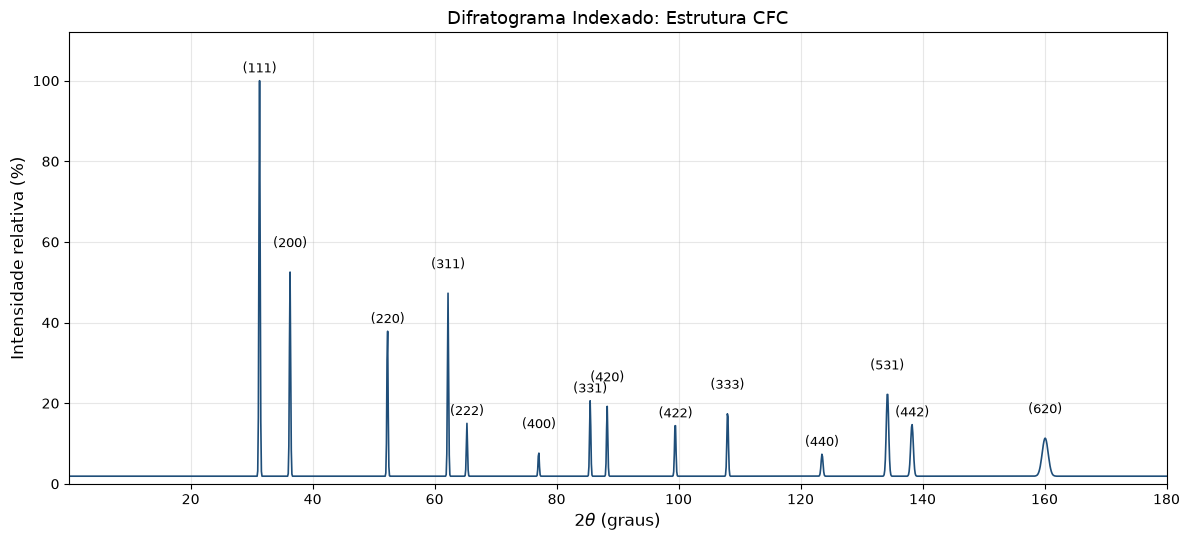

In [23]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(x, y_norm, color="#1f4e79", lw=1.2)   # curva normalizada

# Escreve o (hkl) sobre cada pico. Se houver dois planos para o mesmo pico
# (ex.: "(333) / (511)"), split(" / ")[0] pega apenas o primeiro para o rótulo.
for k, p in enumerate(picos):
    dy = 6 if k % 2 == 0 else 18                  # alterna a altura para não sobrepor
    ax.annotate(tabela["(hkl)"].iloc[k].split(" / ")[0], xy=(x[p], y_norm[p]),
                xytext=(0, dy), textcoords="offset points", ha="center", fontsize=9)

ax.set_xlabel(r"$2\theta$ (graus)", fontsize=12)
ax.set_ylabel("Intensidade relativa (%)", fontsize=12)
ax.set_title(f"Difratograma Indexado: Estrutura {estrutura}", fontsize=13)
ax.set_xlim(x.min(), x.max())
ax.set_ylim(0, 112)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("difratograma_indexado.png", dpi=300)   # figura para o relatório
plt.show()

## 10. Identificação do metal (Item IX)

### Teoria

Na célula **CFC** os átomos se tocam ao longo da **diagonal da face**. Essa diagonal mede $a\sqrt{2}$ e contém 4 raios atômicos (meio átomo em cada vértice e um átomo inteiro no centro da face):

$$4R = a\sqrt{2} \quad\Longrightarrow\quad R = \frac{a\sqrt{2}}{4} \qquad \text{ou} \qquad a = 2R\sqrt{2}$$

Com o raio atômico calculado, comparamos com os metais CFC tabelados e escolhemos o mais próximo. A concordância é medida pelo **desvio relativo**:

$$\delta = \frac{a_{exp} - a_{lit}}{a_{lit}} \times 100\%$$

**Referência dos raios atômicos:** CALLISTER, W. D.; RETHWISCH, D. G. *Ciência e Engenharia de Materiais: uma introdução.* Tabela 3.1. Confiram os valores na edição que vocês usarem e citem-na no relatório.

In [24]:
# Raio atômico a partir do parâmetro de rede experimental (CFC: 4R = a·√2)
R_exp = a_media * np.sqrt(2) / 4
R_erro = a_desvio * np.sqrt(2) / 4      # a incerteza se propaga pelo mesmo fator

# Raios atômicos (nm) de metais CFC - Callister, Tabela 3.1
metais_cfc = {
    "Níquel (Ni)":   0.1246,
    "Cobre (Cu)":    0.1278,
    "Platina (Pt)":  0.1387,
    "Alumínio (Al)": 0.1431,
    "Ouro (Au)":     0.1442,
    "Prata (Ag)":    0.1445,
    "Chumbo (Pb)":   0.1750,
}

comparacao = pd.DataFrame({
    "R literatura (nm)": metais_cfc.values(),
    # parâmetro de rede previsto pela literatura: a = 2R√2
    "a literatura (nm)": [round(2 * r * np.sqrt(2), 4) for r in metais_cfc.values()],
}, index=metais_cfc.keys())
comparacao["desvio de a (%)"] = (100 * (a_media - comparacao["a literatura (nm)"])
                                 / comparacao["a literatura (nm)"]).round(3)

# O metal identificado é o de menor desvio absoluto
metal = comparacao["desvio de a (%)"].abs().idxmin()
a_lit = comparacao.loc[metal, "a literatura (nm)"]
R_lit = comparacao.loc[metal, "R literatura (nm)"]
desvio = comparacao.loc[metal, "desvio de a (%)"]

print(f"Raio atômico experimental: R = {R_exp:.4f} ± {R_erro:.5f} nm")
print(f"Metal identificado: {metal}")
print(f"  a experimental = {a_media:.4f} nm | a literatura = {a_lit:.4f} nm | desvio = {desvio:+.3f} %")
comparacao.sort_values("desvio de a (%)", key=abs)

Raio atômico experimental: R = 0.1750 ± 0.00004 nm
Metal identificado: Chumbo (Pb)
  a experimental = 0.4950 nm | a literatura = 0.4950 nm | desvio = -0.005 %


,R literatura (nm),a literatura (nm),desvio de a (%)
Chumbo (Pb),0.1750,0.4950,-0.005
Prata (Ag),0.1445,0.4087,21.110
Ouro (Au),0.1442,0.4079,21.347
Alumínio (Al),0.1431,0.4047,22.307
Platina (Pt),0.1387,0.3923,26.173
Cobre (Cu),0.1278,0.3615,36.923
Níquel (Ni),0.1246,0.3524,40.458


## 11. Estrutura cristalina e planos dos picos mais intensos (Item X)

Os dois picos mais intensos são **(111)**, com 100%, e **(200)**, com 52,5%.

- **Plano (111):** corta os eixos em x = y = z = 1 e forma um triângulo equilátero entre três vértices do cubo. É o **plano de maior densidade atômica** da CFC, com empacotamento compacto e arranjo hexagonal.
- **Plano (200):** corta o eixo x em ½ e é paralelo a y e z. É um quadrado no **meio do cubo**, paralelo à face. A reflexão (100) é extinta na CFC, porque o plano de átomos do centro das faces fica no meio do caminho e cancela a onda. Por isso o primeiro pico dessa família é o (200), com $d_{200} = a/2$.

### Densidade planar

A densidade planar é $DP = \dfrac{\text{nº de átomos centrados no plano}}{\text{área do plano}}$:

| Plano | Área na célula | Átomos | DP |
|---|---|---|---|
| (111) | triângulo de lado $a\sqrt2$: $\frac{\sqrt3}{2}a^2$ | 3 × 1/6 (vértices) + 3 × 1/2 (arestas) = 2 | $\frac{4}{\sqrt3\,a^2}$ |
| (200) | quadrado: $a^2$ | 4 × 1/4 (vértices) + 1 (centro) = 2 | $\frac{2}{a^2}$ |

O plano (111) é o mais denso e corresponde ao pico mais intenso, o que é coerente com o item III do roteiro.

DP(111) = 9.43 átomos/nm²   |   DP(200) = 8.16 átomos/nm²
DP(111)/DP(200) = 1.155


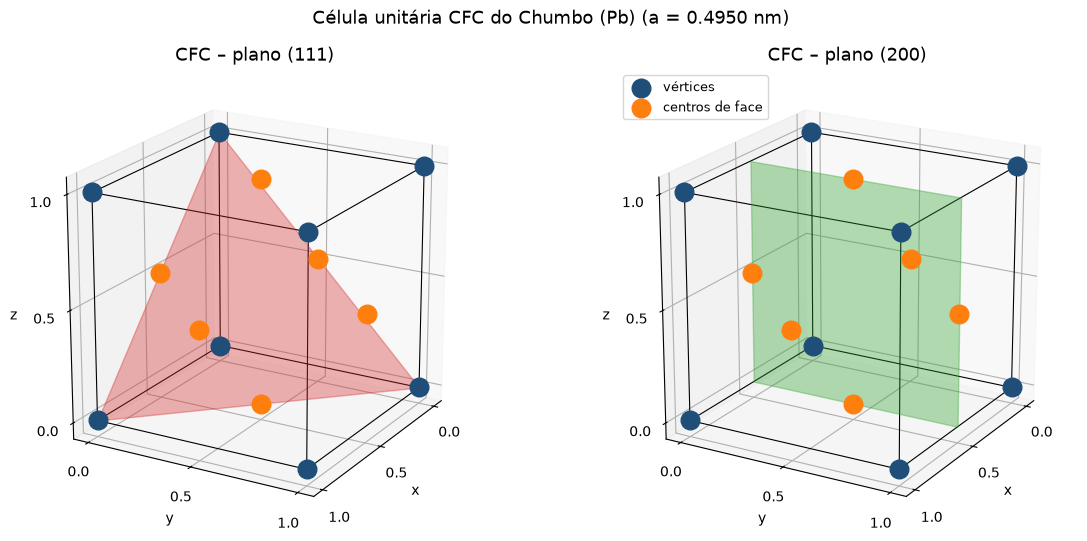

In [25]:
# Densidade planar dos dois planos (átomos/nm²) com o a experimental
DP_111 = 4 / (np.sqrt(3) * a_media**2)
DP_200 = 2 / a_media**2
print(f"DP(111) = {DP_111:.2f} átomos/nm²   |   DP(200) = {DP_200:.2f} átomos/nm²")
print(f"DP(111)/DP(200) = {DP_111/DP_200:.3f}")

# ---------------------------------------------------------------
# Desenho 3D da célula CFC com os planos (111) e (200)
# ---------------------------------------------------------------
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Posições dos átomos em coordenadas fracionárias (a = 1)
vertices = [(i, j, k) for i in (0, 1) for j in (0, 1) for k in (0, 1)]          # 8 vértices
faces = [(0.5, 0.5, 0), (0.5, 0.5, 1), (0.5, 0, 0.5), (0.5, 1, 0.5),             # 6 centros
         (0, 0.5, 0.5), (1, 0.5, 0.5)]                                           #   de face

# Arestas do cubo: pares de vértices que diferem em uma única coordenada
arestas = [(p, q) for p in vertices for q in vertices
           if p < q and sum(abs(np.subtract(p, q))) == 1]

planos = {
    "(111)": [(1, 0, 0), (0, 1, 0), (0, 0, 1)],                       # triângulo
    "(200)": [(0.5, 0, 0), (0.5, 1, 0), (0.5, 1, 1), (0.5, 0, 1)],    # quadrado em x = 1/2
}
cores = {"(111)": "#d62728", "(200)": "#2ca02c"}

fig = plt.figure(figsize=(12, 5.5))
for n_sub, (nome, poligono) in enumerate(planos.items(), start=1):
    ax = fig.add_subplot(1, 2, n_sub, projection="3d")
    for p, q in arestas:                                   # arestas da célula
        ax.plot(*zip(p, q), color="k", lw=0.8)
    ax.add_collection3d(Poly3DCollection([poligono], alpha=0.35,
                                         facecolor=cores[nome], edgecolor=cores[nome]))
    ax.scatter(*zip(*vertices), s=180, c="#1f4e79", depthshade=False, label="vértices")
    ax.scatter(*zip(*faces), s=180, c="#ff7f0e", depthshade=False, label="centros de face")
    ax.set_title(f"CFC – plano {nome}", fontsize=13)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1]); ax.set_zticks([0, 0.5, 1])
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=30)
ax.legend(loc="upper left", fontsize=9)
fig.suptitle(f"Célula unitária CFC do {metal} (a = {a_media:.4f} nm)", fontsize=13)
fig.tight_layout()
fig.savefig("estrutura_cfc_planos.png", dpi=300)
plt.show()

## 12. Questão D: elemento de liga em solução sólida

**O que muda no difratograma quando se forma uma solução sólida?**

1. **Deslocamento dos picos.** Os átomos de soluto têm raio diferente dos átomos do solvente (Pb) e, por isso, distorcem a rede e mudam o parâmetro $a$. Em soluções sólidas substitucionais, $a$ varia aproximadamente de forma linear com a fração do soluto (**lei de Vegard**): $a_{liga} \approx (1-x)\,a_{Pb} + x\,a_{soluto}$.
   - Soluto **maior** que o Pb, ou soluto **intersticial**: $a$ aumenta, $d$ aumenta e, pela Lei de Bragg, os picos vão para **2θ menores**.
   - Soluto **menor**: $a$ diminui e os picos vão para **2θ maiores**.
   - Diferenciando a Lei de Bragg, $\Delta(2\theta) = -2\tan\theta\,\dfrac{\Delta d}{d}$. Assim, o deslocamento é **maior nos picos de ângulo alto**.

2. **Mesma sequência de picos.** Se o soluto ocupar as posições da rede de forma aleatória, a estrutura continua CFC e as regras de extinção são as mesmas. Não aparecem picos novos; a sequência S = 3, 4, 8, 11, ... é mantida.

3. **Intensidades relativas levemente diferentes.** O fator de espalhamento passa a ser uma média ponderada, $f_{médio} = (1-x)f_{Pb} + x f_{soluto}$, o que altera $|F|^2$.

4. **Alargamento dos picos.** Pequenas variações locais de composição e as microdeformações que o soluto introduz na rede alargam os picos.

5. **Se o limite de solubilidade for ultrapassado,** forma-se uma **segunda fase**, que aparece como **picos novos** com a estrutura própria dessa fase.

## 13. Questão E: difratograma e fração volumétrica das fases

**Quais informações do difratograma estão ligadas à concentração volumétrica de cada fase?**

As **intensidades dos picos**, mais precisamente a **intensidade integrada** (área sob o pico), e não só a altura. Num material com várias fases, a intensidade de um pico *i* da fase α é proporcional à fração volumétrica dessa fase:

$$I_{i\alpha} = \frac{K \, R_{i\alpha}\, V_\alpha}{2\mu_m}$$

Os termos são:
- $K$: constante do equipamento;
- $R_{i\alpha}$: fator que reúne $|F|^2$, multiplicidade, Lorentz-polarização e o volume da célula;
- $V_\alpha$: fração volumétrica da fase α;
- $\mu_m$: coeficiente de absorção linear da mistura.

Comparando as intensidades integradas de picos de fases diferentes, obtém-se a proporção entre elas. Os métodos mais usados são:
- **comparação direta**: razão entre picos de duas fases, por exemplo austenita/martensita em aços;
- **padrão interno** e **RIR** (*Reference Intensity Ratio*, $I/I_{corundum}$);
- **método de Rietveld**: ajusta o difratograma inteiro e é o mais preciso.

**Cuidados:** **textura** (orientação preferencial) e diferenças de **absorção** entre as fases distorcem as intensidades. Outro ponto é que a **posição** dos picos identifica *quais* fases estão presentes (análise qualitativa), enquanto a **intensidade** mede *quanto* de cada fase existe (análise quantitativa).

## 14. Resumo dos resultados

In [26]:
i_ord = tabela["I relativa (%)"].sort_values(ascending=False).index[:2]   # 2 picos mais intensos

resumo_final = pd.DataFrame({"Resultado": [
    f"{len(tabela)} picos, de {tabela['2θ (°)'].min()}° a {tabela['2θ (°)'].max()}° (2θ)",
    f"{LAMBDA} nm (Cu Kα)",
    f"{estrutura} (variação de sen²θ/S = {resumo[estrutura]:.2f} %)",
    f"{(sen2 / S).mean():.5f}",
    f"{a_media:.4f} ± {a_desvio:.4f} nm (erro padrão da média: {a_erro:.5f} nm)",
    f"{R_exp:.4f} ± {R_erro:.5f} nm",
    f"{metal}",
    f"a = {a_lit:.4f} nm | R = {R_lit:.4f} nm (Callister, Tab. 3.1)",
    f"{desvio:+.3f} %",
    " e ".join(f"{tabela.loc[i, '(hkl)']} ({tabela.loc[i, '2θ (°)']}°, {tabela.loc[i, 'I relativa (%)']}%)" for i in i_ord),
]}, index=[
    "Picos de difração",
    "Comprimento de onda λ",
    "Estrutura cristalina",
    "Constante sen²θ/S = λ²/4a²",
    "Parâmetro de rede a",
    "Raio atômico R",
    "Metal identificado",
    "Valor de literatura",
    "Desvio em relação à literatura",
    "Dois picos mais intensos",
])
pd.set_option("display.max_colwidth", None)   # mostra o texto completo de cada célula
display(resumo_final)

# Tabela final do item b do relatório (todas as colunas pedidas)
tabela_relatorio = tabela[["2θ (°)", "I relativa (%)", "d (nm)", "sen²θ", "S", "sen²θ/S", "(hkl)", "a (nm)", "Δa (nm)"]]
tabela_relatorio.to_csv("tabela_resultados.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("Tabela salva em tabela_resultados.csv (abre direto no Excel, com vírgula decimal)")
tabela_relatorio

,Resultado
Picos de difração,"14 picos, de 31.3° a 160.1° (2θ)"
Comprimento de onda λ,0.1541838 nm (Cu Kα)
Estrutura cristalina,CFC (variação de sen²θ/S = 0.04 %)
Constante sen²θ/S = λ²/4a²,0.02426
Parâmetro de rede a,0.4950 ± 0.0001 nm (erro padrão da média: 0.00003 nm)
Raio atômico R,0.1750 ± 0.00004 nm
Metal identificado,Chumbo (Pb)
Valor de literatura,"a = 0.4950 nm | R = 0.1750 nm (Callister, Tab. 3.1)"
Desvio em relação à literatura,-0.005 %
Dois picos mais intensos,"(111) (31.3°, 100.0%) e (200) (36.3°, 52.5%)"


Tabela salva em tabela_resultados.csv (abre direto no Excel, com vírgula decimal)


,2θ (°),I relativa (%),d (nm),sen²θ,S,sen²θ/S,(hkl),a (nm),Δa (nm)
Pico,,,,,,,,,
1,31.3,100.0,0.2858,0.0728,3,0.02426,(111),0.4950,0.00077
2,36.3,52.5,0.2475,0.0970,4,0.02426,(200),0.4950,0.00066
3,52.3,37.8,0.1749,0.1942,8,0.02428,(220),0.4948,0.00044
4,62.2,47.3,0.1492,0.2668,11,0.02426,(311),0.4950,0.00036
5,65.3,15.0,0.1429,0.2911,12,0.02426,(222),0.4950,0.00034
6,77.1,7.6,0.1237,0.3884,16,0.02427,(400),0.4948,0.00027
7,85.5,20.6,0.1136,0.4608,19,0.02425,(331),0.4950,0.00023
8,88.3,19.2,0.1107,0.4852,20,0.02426,(420),0.4950,0.00022
9,99.5,14.4,0.1010,0.5825,24,0.02427,(422),0.4948,0.00018
